# 성동구 상권 환경 데이터 Descriptive Statistics

## 목적
2021~2025년 서울시 상권분석서비스 데이터를 이용하여 성동구 음식점 관련 상권 환경의 기초통계량과 요약 차트를 생성합니다.

### 사용 데이터
- 점포-상권 (2021~2025)
- 추정매출-상권 (2021~2025)
- 상주인구-상권
- 직장인구-상권
- 길단위인구-상권
- 집객시설-상권
- 영역-상권 SHP

> SHP에서 성동구 상권코드를 추출한 뒤 각 상권 CSV를 해당 코드로 필터링합니다.


## 1. 라이브러리 불러오기


In [8]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import glob
import os
import unicodedata

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


In [31]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

## 2. 데이터 경로와 파일 검색 함수

이 노트북과 데이터 파일이 같은 폴더에 있으면 `DATA_DIR = "."`를 그대로 사용합니다.
다른 폴더에 있다면 경로만 수정하세요.


In [9]:
DATA_DIR = "."

def find_files(keyword, extension=".csv"):
    files = glob.glob(os.path.join(DATA_DIR, f"*{extension}"))
    result = []

    for file in files:
        filename = unicodedata.normalize("NFC", os.path.basename(file))
        if keyword in filename:
            result.append(file)

    return sorted(result)


## 3. 성동구 상권코드 추출


In [10]:
shp_files = find_files("영역-상권", ".shp")

if len(shp_files) == 0:
    raise FileNotFoundError("영역-상권 SHP 파일을 찾을 수 없습니다.")

area = gpd.read_file(shp_files[0])

print("SHP shape:", area.shape)
print("SHP columns:")
print(area.columns.tolist())


SHP shape: (1650, 12)
SHP columns:
['TRDAR_SE_C', 'TRDAR_SE_1', 'TRDAR_CD', 'TRDAR_CD_N', 'XCNTS_VALU', 'YDNTS_VALU', 'SIGNGU_CD', 'SIGNGU_CD_', 'ADSTRD_CD', 'ADSTRD_CD_', 'RELM_AR', 'geometry']


In [11]:
seongdong_area = area[
    area["SIGNGU_CD_"] == "성동구"
].copy()

seongdong_codes = set(
    seongdong_area["TRDAR_CD"].astype(str)
)

print("성동구 상권 수:", len(seongdong_codes))

display(
    seongdong_area[
        ["TRDAR_CD", "TRDAR_CD_N", "SIGNGU_CD_"]
    ].head(10)
)


성동구 상권 수: 55


,TRDAR_CD,TRDAR_CD_N,SIGNGU_CD_
199,3110110,상왕십리역 6번,성동구
200,3130073,뚝도시장,성동구
201,3130072,성동용답상가시장,성동구
202,3130071,성수역 골목형상점가,성동구
203,3130069,"한양대앞상점가(한양시장, 왕십리맛골목)",성동구
204,3130068,마장축산물시장,성동구
205,3130070,뚝섬역상점가,성동구
206,3130067,왕십리도선동상점가,성동구
207,3130066,행당시장상점가,성동구
208,3130065,무학봉상점가,성동구


## 4. 점포 데이터 2021~2025 통합


In [12]:
store_files = find_files("점포-상권")

print("점포 파일 수:", len(store_files))
for f in store_files:
    print(os.path.basename(f))


점포 파일 수: 5
서울시 상권분석서비스(점포-상권)_2024년.csv
서울시 상권분석서비스(점포-상권)_2025년.csv
서울시_상권분석서비스(점포-상권)_2021년.csv
서울시_상권분석서비스(점포-상권)_2022년.csv
서울시_상권분석서비스(점포-상권)_2023년.csv


In [13]:
rename_2025 = {
    "stdr_yyqu_cd": "기준_년분기_코드",
    "trdar_se_cd": "상권_구분_코드",
    "trdar_se_cd_nm": "상권_구분_코드_명",
    "trdar_cd": "상권_코드",
    "trdar_cd_nm": "상권_코드_명",
    "svc_induty_cd": "서비스_업종_코드",
    "svc_induty_cd_nm": "서비스_업종_코드_명",
    "stor_co": "점포_수",
    "similr_induty_stor_co": "유사_업종_점포_수",
    "opbiz_rt": "개업_율",
    "opbiz_stor_co": "개업_점포_수",
    "clsbiz_rt": "폐업_률",
    "clsbiz_stor_co": "폐업_점포_수",
    "frc_stor_co": "프랜차이즈_점포_수"
}

store_list = []

for file in store_files:
    temp = pd.read_csv(file, encoding="cp949")
    temp = temp.rename(columns=rename_2025)
    store_list.append(temp)

store = pd.concat(store_list, ignore_index=True)

print("전체 점포 데이터:", store.shape)
print(store.columns.tolist())


전체 점포 데이터: (1528872, 14)
['기준_년분기_코드', '상권_구분_코드', '상권_구분_코드_명', '상권_코드', '상권_코드_명', '서비스_업종_코드', '서비스_업종_코드_명', '점포_수', '유사_업종_점포_수', '개업_율', '개업_점포_수', '폐업_률', '폐업_점포_수', '프랜차이즈_점포_수']


### 성동구 + 2021~2025 필터링


In [14]:
store["상권_코드"] = store["상권_코드"].astype(str)

store_sd = store[
    store["상권_코드"].isin(seongdong_codes)
].copy()

store_sd = store_sd[
    store_sd["기준_년분기_코드"].between(20211, 20254)
].copy()

print("서울 전체:", store.shape)
print("성동구:", store_sd.shape)


서울 전체: (1528872, 14)
성동구: (51131, 14)


### 음식 관련 업종 추출

상권분석서비스의 음식 관련 서비스 업종을 기준으로 추출합니다.
Tier 0 일반음식점 정의와 완전히 동일하지 않을 수 있으므로 최종 Cox 모형에서는 업종 범위를 다시 확인할 필요가 있습니다.


In [15]:
food_categories = [
    "한식음식점",
    "중식음식점",
    "일식음식점",
    "양식음식점",
    "분식전문점",
    "치킨전문점",
    "호프-간이주점",
    "커피-음료",
    "제과점"
]

store_food = store_sd[
    store_sd["서비스_업종_코드_명"].isin(food_categories)
].copy()

print("음식 관련 점포 관측치:", store_food.shape)

display(
    store_food["서비스_업종_코드_명"]
    .value_counts()
    .rename("관측치 수")
    .to_frame()
)


음식 관련 점포 관측치: (7870, 14)


,관측치 수
서비스_업종_코드_명,
한식음식점,1100
커피-음료,1060
분식전문점,915
호프-간이주점,893
일식음식점,814
양식음식점,798
치킨전문점,793
제과점,774
중식음식점,723


### 점포 데이터 기초통계량


In [16]:
store_vars = [
    "점포_수",
    "유사_업종_점포_수",
    "개업_율",
    "개업_점포_수",
    "폐업_률",
    "폐업_점포_수",
    "프랜차이즈_점포_수"
]

store_stats = store_food[store_vars].describe().T
store_stats["median"] = store_food[store_vars].median()

store_stats = store_stats[
    ["count", "mean", "std", "median", "min", "max"]
]

display(store_stats.round(2))


,count,mean,std,median,min,max
점포_수,"7,870.00",8.06,13.95,3.00,0.00,144.00
유사_업종_점포_수,"7,870.00",9.59,15.97,4.00,0.00,161.00
개업_율,"7,870.00",4.29,12.58,0.00,0.00,100.00
개업_점포_수,"7,870.00",0.41,0.96,0.00,0.00,11.00
폐업_률,"7,870.00",3.81,13.31,0.00,0.00,300.00
폐업_점포_수,"7,870.00",0.35,0.84,0.00,0.00,10.00
프랜차이즈_점포_수,"7,870.00",1.52,2.78,1.00,0.00,24.00


## 5. 추정매출 데이터 2021~2025


In [17]:
sales_files = find_files("추정매출-상권")

print("매출 파일 수:", len(sales_files))
for f in sales_files:
    print(os.path.basename(f))


매출 파일 수: 5
서울시 상권분석서비스(추정매출-상권)_2024년.csv
서울시 상권분석서비스(추정매출-상권)_2025년.csv
서울시_상권분석서비스(추정매출-상권)_2021년.csv
서울시_상권분석서비스(추정매출-상권)_2022년.csv
서울시_상권분석서비스(추정매출-상권)_2023년.csv


In [18]:
sales_list = []

for file in sales_files:
    temp = pd.read_csv(file, encoding="cp949")
    sales_list.append(temp)

sales = pd.concat(sales_list, ignore_index=True)

sales["상권_코드"] = sales["상권_코드"].astype(str)

sales_sd = sales[
    sales["상권_코드"].isin(seongdong_codes)
].copy()

sales_sd = sales_sd[
    sales_sd["기준_년분기_코드"].between(20211, 20254)
].copy()

sales_food = sales_sd[
    sales_sd["서비스_업종_코드_명"].isin(food_categories)
].copy()

print("성동구 음식 관련 매출 관측치:", sales_food.shape)


성동구 음식 관련 매출 관측치: (4176, 55)


In [19]:
sales_vars = [
    "당월_매출_금액",
    "당월_매출_건수",
    "주중_매출_금액",
    "주말_매출_금액"
]

sales_stats = sales_food[sales_vars].describe().T
sales_stats["median"] = sales_food[sales_vars].median()

sales_stats = sales_stats[
    ["count", "mean", "std", "median", "min", "max"]
]

display(sales_stats.round(2))


,count,mean,std,median,min,max
당월_매출_금액,"4,176.00","717,033,730.89","1,609,278,425.58","193,194,502.50","3,936.00","17,274,259,927.00"
당월_매출_건수,"4,176.00","30,073.77","58,976.19","10,738.00",3.00,"581,604.00"
주중_매출_금액,"4,176.00","534,679,065.32","1,239,363,895.84","148,681,869.50",0.00,"13,794,741,978.00"
주말_매출_금액,"4,176.00","182,354,665.56","384,715,289.00","47,530,890.50",0.00,"3,577,777,643.00"


## 6. 상주인구 데이터


In [20]:
resident_file = find_files("상주인구-상권")[0]

resident = pd.read_csv(resident_file, encoding="cp949")
resident["상권_코드"] = resident["상권_코드"].astype(str)

resident_sd = resident[
    resident["상권_코드"].isin(seongdong_codes)
].copy()

resident_sd = resident_sd[
    resident_sd["기준_년분기_코드"].between(20211, 20254)
].copy()

resident_vars = [
    "총_상주인구_수",
    "총_가구_수",
    "아파트_가구_수",
    "비_아파트_가구_수"
]

resident_stats = resident_sd[resident_vars].describe().T
resident_stats["median"] = resident_sd[resident_vars].median()
resident_stats = resident_stats[
    ["count", "mean", "std", "median", "min", "max"]
]

display(resident_stats.round(2))


,count,mean,std,median,min,max
총_상주인구_수,"1,100.00","1,650.52","1,392.27","1,348.00",3.00,"8,370.00"
총_가구_수,"1,100.00",926.29,769.61,771.00,1.00,"4,002.00"
아파트_가구_수,"1,100.00",0.00,0.00,0.00,0.00,0.00
비_아파트_가구_수,"1,100.00",926.29,769.61,771.00,1.00,"4,002.00"


## 7. 직장인구 데이터


In [21]:
worker_file = find_files("직장인구-상권")[0]

worker = pd.read_csv(worker_file, encoding="cp949")
worker["상권_코드"] = worker["상권_코드"].astype(str)

worker_sd = worker[
    worker["상권_코드"].isin(seongdong_codes)
].copy()

worker_sd = worker_sd[
    worker_sd["기준_년분기_코드"].between(20211, 20254)
].copy()

worker_vars = ["총_직장_인구_수"]

worker_stats = worker_sd[worker_vars].describe().T
worker_stats["median"] = worker_sd[worker_vars].median()
worker_stats = worker_stats[
    ["count", "mean", "std", "median", "min", "max"]
]

display(worker_stats.round(2))


,count,mean,std,median,min,max
총_직장_인구_수,"1,100.00","1,194.79","2,189.77",496.00,19.00,"15,712.00"


## 8. 길단위 유동인구 데이터


In [22]:
floating_file = find_files("길단위인구-상권")[0]

floating = pd.read_csv(floating_file, encoding="cp949")
floating["상권_코드"] = floating["상권_코드"].astype(str)

floating_sd = floating[
    floating["상권_코드"].isin(seongdong_codes)
].copy()

floating_sd = floating_sd[
    floating_sd["기준_년분기_코드"].between(20211, 20254)
].copy()

floating_vars = ["총_유동인구_수"]

floating_stats = floating_sd[floating_vars].describe().T
floating_stats["median"] = floating_sd[floating_vars].median()
floating_stats = floating_stats[
    ["count", "mean", "std", "median", "min", "max"]
]

display(floating_stats.round(2))


,count,mean,std,median,min,max
총_유동인구_수,"1,100.00","685,327.51","540,940.73","541,334.50","36,270.00","3,044,311.00"


## 9. 집객시설 데이터


In [23]:
facility_file = find_files("집객시설-상권")[0]

facility = pd.read_csv(facility_file, encoding="cp949")
facility["상권_코드"] = facility["상권_코드"].astype(str)

facility_sd = facility[
    facility["상권_코드"].isin(seongdong_codes)
].copy()

facility_sd = facility_sd[
    facility_sd["기준_년분기_코드"].between(20211, 20254)
].copy()

facility_vars = [
    "집객시설_수",
    "관공서_수",
    "은행_수",
    "종합병원_수",
    "일반_병원_수",
    "약국_수",
    "초등학교_수",
    "중학교_수",
    "고등학교_수",
    "대학교_수",
    "지하철_역_수",
    "버스_정거장_수"
]

existing_facility_vars = [
    col for col in facility_vars
    if col in facility_sd.columns
]

facility_stats = facility_sd[existing_facility_vars].describe().T
facility_stats["median"] = facility_sd[existing_facility_vars].median()
facility_stats = facility_stats[
    ["count", "mean", "std", "median", "min", "max"]
]

display(facility_stats.round(2))


,count,mean,std,median,min,max
집객시설_수,"1,100.00",14.96,14.88,10.00,1.00,71.00
관공서_수,460.00,1.39,0.64,1.00,1.00,3.00
은행_수,360.00,2.06,1.99,1.00,1.00,9.00
종합병원_수,0.00,NaN,NaN,NaN,NaN,NaN
일반_병원_수,80.00,1.00,0.00,1.00,1.00,1.00
약국_수,720.00,2.53,1.89,2.00,1.00,8.00
초등학교_수,40.00,1.00,0.00,1.00,1.00,1.00
중학교_수,0.00,NaN,NaN,NaN,NaN,NaN
고등학교_수,20.00,1.00,0.00,1.00,1.00,1.00
대학교_수,20.00,1.00,0.00,1.00,1.00,1.00


## 10. 결측치 확인


In [24]:
datasets = {
    "Store": store_food,
    "Sales": sales_food,
    "Resident": resident_sd,
    "Worker": worker_sd,
    "Floating": floating_sd,
    "Facility": facility_sd
}

for name, df in datasets.items():
    print("\n====================")
    print(name)
    print("====================")

    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    if len(missing) == 0:
        print("결측치 없음")
    else:
        print(missing)



Store
결측치 없음

Sales
결측치 없음

Resident
결측치 없음

Worker
결측치 없음

Floating
결측치 없음

Facility
버스_터미널_수    1100
종합병원_수      1100
중학교_수       1100
백화점_수       1100
공항_수        1100
철도_역_수      1100
대학교_수       1080
고등학교_수      1080
극장_수        1080
숙박_시설_수     1080
초등학교_수      1060
유치원_수       1040
슈퍼마켓_수      1040
일반_병원_수     1020
지하철_역_수      980
은행_수         740
관공서_수        640
약국_수         380
버스_정거장_수     120
dtype: int64


## 11. 최종 상권 환경 Descriptive Statistics


In [25]:
summary_data = {
    "Store Count": store_food["점포_수"],
    "Opening Rate": store_food["개업_율"],
    "Closure Rate": store_food["폐업_률"],
    "Franchise Stores": store_food["프랜차이즈_점포_수"],
    "Monthly Sales": sales_food["당월_매출_금액"],
    "Sales Transactions": sales_food["당월_매출_건수"],
    "Resident Population": resident_sd["총_상주인구_수"],
    "Worker Population": worker_sd["총_직장_인구_수"],
    "Floating Population": floating_sd["총_유동인구_수"],
    "Attracting Facilities": facility_sd["집객시설_수"]
}

summary_rows = []

for name, data in summary_data.items():
    data = pd.to_numeric(data, errors="coerce").dropna()

    summary_rows.append({
        "Variable": name,
        "N": len(data),
        "Mean": data.mean(),
        "SD": data.std(),
        "Median": data.median(),
        "Min": data.min(),
        "Max": data.max()
    })

environment_stats = pd.DataFrame(summary_rows)

display(environment_stats.round(2))


,Variable,N,Mean,SD,Median,Min,Max
0,Store Count,7870,8.06,13.95,3.00,0,144
1,Opening Rate,7870,4.29,12.58,0.00,0,100
2,Closure Rate,7870,3.81,13.31,0.00,0,300
3,Franchise Stores,7870,1.52,2.78,1.00,0,24
4,Monthly Sales,4176,"717,033,730.89","1,609,278,425.58","193,194,502.50",3936,17274259927
5,Sales Transactions,4176,"30,073.77","58,976.19","10,738.00",3,581604
6,Resident Population,1100,"1,650.52","1,392.27","1,348.00",3,8370
7,Worker Population,1100,"1,194.79","2,189.77",496.00,19,15712
8,Floating Population,1100,"685,327.51","540,940.73","541,334.50",36270,3044311
9,Attracting Facilities,1100,14.96,14.88,10.00,1,71


## 12. 요약 차트


### Figure 1. 연도별 평균 개업률과 폐업률


,개업_율,폐업_률
연도,,
2021,5.25,3.19
2022,4.81,3.48
2023,4.37,3.84
2024,3.58,4.19
2025,3.48,4.35


/var/folders/rw/wk8lm3652dxcbm3ss6qg0yj40000gn/T/ipykernel_22809/2597605672.py:18: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/rw/wk8lm3652dxcbm3ss6qg0yj40000gn/T/ipykernel_22809/2597605672.py:18: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/rw/wk8lm3652dxcbm3ss6qg0yj40000gn/T/ipykernel_22809/2597605672.py:18: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/rw/wk8lm3652dxcbm3ss6qg0yj40000gn/T/ipykernel_22809/2597605672.py:18: UserWarning: Glyph 54224 (\N{HANGUL SYLLABLE PYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/rw/wk8lm3652dxcbm3ss6qg0yj40000gn/T/ipykernel_22809/2597605672.py:18: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/kim-eunhye/Library/Python/3.9/lib/python/site-p

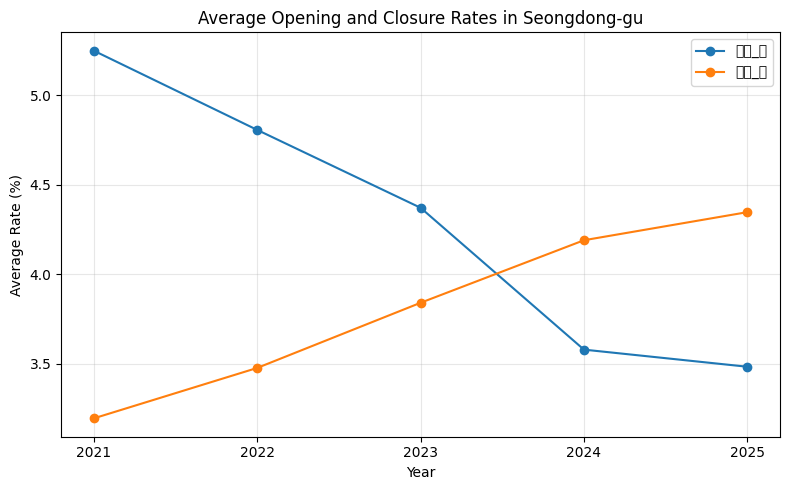

In [26]:
store_food["연도"] = store_food["기준_년분기_코드"] // 10

yearly_rates = (
    store_food
    .groupby("연도")[["개업_율", "폐업_률"]]
    .mean()
)

display(yearly_rates.round(2))

yearly_rates.plot(marker="o", figsize=(8, 5))

plt.xlabel("Year")
plt.ylabel("Average Rate (%)")
plt.title("Average Opening and Closure Rates in Seongdong-gu")
plt.xticks(range(2021, 2026))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Figure 2. 연도별 평균 매출


,Average Monthly Sales
연도,
2021,"587,541,774.50"
2022,"694,906,985.33"
2023,"757,531,202.75"
2024,"780,753,457.98"
2025,"759,140,331.04"


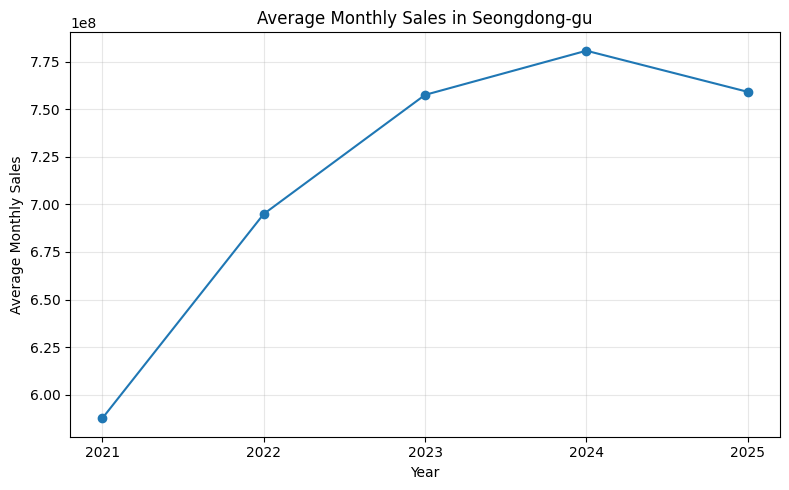

In [27]:
sales_food["연도"] = sales_food["기준_년분기_코드"] // 10

yearly_sales = (
    sales_food
    .groupby("연도")["당월_매출_금액"]
    .mean()
)

display(yearly_sales.to_frame("Average Monthly Sales"))

yearly_sales.plot(marker="o", figsize=(8, 5))

plt.xlabel("Year")
plt.ylabel("Average Monthly Sales")
plt.title("Average Monthly Sales in Seongdong-gu")
plt.xticks(range(2021, 2026))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Figure 3. 연도별 평균 유동인구


,Average Floating Population
연도,
2021,"691,217.70"
2022,"688,821.44"
2023,"685,019.98"
2024,"685,208.95"
2025,"676,369.49"


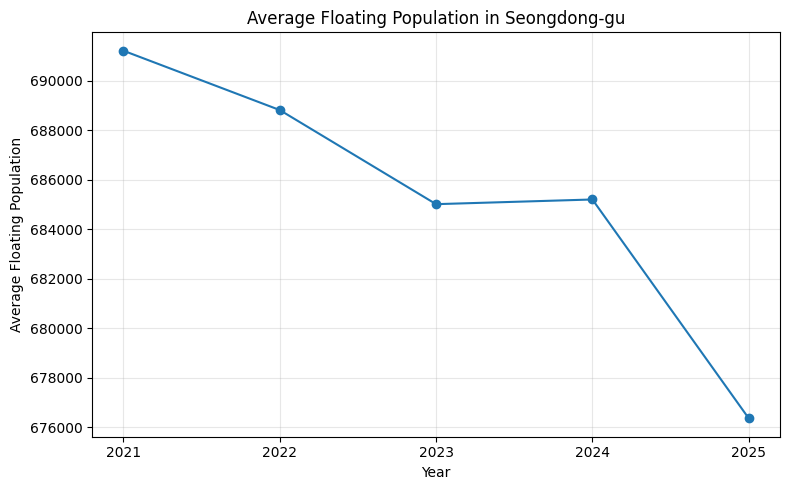

In [28]:
floating_sd["연도"] = floating_sd["기준_년분기_코드"] // 10

yearly_floating = (
    floating_sd
    .groupby("연도")["총_유동인구_수"]
    .mean()
)

display(yearly_floating.to_frame("Average Floating Population"))

yearly_floating.plot(marker="o", figsize=(8, 5))

plt.xlabel("Year")
plt.ylabel("Average Floating Population")
plt.title("Average Floating Population in Seongdong-gu")
plt.xticks(range(2021, 2026))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Figure 4. 음식 업종별 평균 폐업률



,Average Closure Rate
서비스_업종_코드_명,
제과점,2.91
중식음식점,3.19
한식음식점,3.32
호프-간이주점,3.36
일식음식점,3.37
치킨전문점,3.54
분식전문점,4.14
커피-음료,4.78
양식음식점,5.50


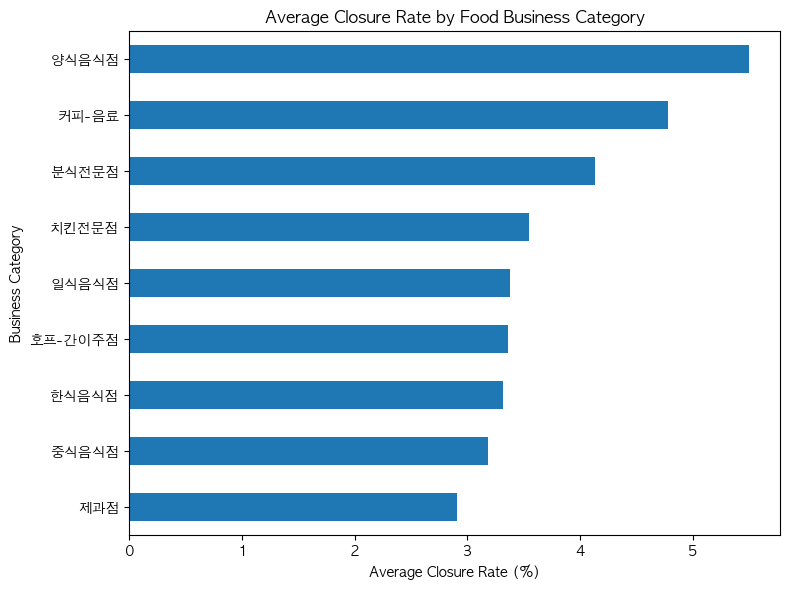

In [32]:
closure_by_category = (
    store_food
    .groupby("서비스_업종_코드_명")["폐업_률"]
    .mean()
    .sort_values()
)

display(closure_by_category.to_frame("Average Closure Rate"))

closure_by_category.plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Average Closure Rate (%)")
plt.ylabel("Business Category")
plt.title("Average Closure Rate by Food Business Category")
plt.tight_layout()
plt.show()


## 13. 결과 저장


In [33]:
environment_stats.round(2).to_csv(
    "seongdong_environment_descriptive_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

store_stats.round(2).to_csv(
    "store_descriptive_statistics.csv",
    encoding="utf-8-sig"
)

sales_stats.round(2).to_csv(
    "sales_descriptive_statistics.csv",
    encoding="utf-8-sig"
)

print("CSV 저장 완료")


CSV 저장 완료


## 다음 단계: 리뷰 데이터

`naver_seongsu_reviews.csv`가 준비되면 이 노트북 뒤에 다음 분석을 추가할 수 있습니다.

- 전체 리뷰 수 / 음식점 수
- 음식점별 리뷰 수
- 별점 평균·표준편차·중앙값
- 웨이팅 시간 분포
- 예약 여부
- 방문 시점 분포
- 음식점별 평균 별점
- 리뷰 결측치
- 리뷰 관련 요약 차트
